In [4]:
import math
import random
import time
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
QUICK = False
PROTO_EPOCHS = 2 if QUICK else 25
FINAL_EPOCHS = 2 if QUICK else 40
PROTO_BS = 128
FINAL_BS = 64

DATA_DIRS = {75: Path("A1_data_75"), 150: Path("A1_data_150")}
OUT_DIR = Path("task2_outputs")
OUT_DIR.mkdir(exist_ok=True)


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed()
print("device:", DEVICE)
for r, p in DATA_DIRS.items():
    print(r, p.resolve(), (p / "images.npy").exists(), (p / "labels.npy").exists())

device: cuda
75 D:\Assignments_LU\IDL\Assignment 1\dl-Ass1\A1_data_75 True True
150 D:\Assignments_LU\IDL\Assignment 1\dl-Ass1\A1_data_150 True True


In [5]:
class Loader:
    def __init__(self, x, t, batch_size, shuffle, mean, std):
        self.x, self.t, self.bs, self.shuffle = x, t, batch_size, shuffle
        self.mean, self.std = mean, std

    def __len__(self):
        return (len(self.x) + self.bs - 1) // self.bs

    def __iter__(self):
        n = len(self.x)
        dev = self.x.device
        idx = torch.randperm(n, device=dev) if self.shuffle else torch.arange(n, device=dev)
        for i in range(0, n, self.bs):
            b = idx[i:i + self.bs]
            xb = (self.x[b].float() / 255.0 - self.mean) / self.std
            yield xb.unsqueeze(1), self.t[b]


def to_uint8(a):
    if a.dtype == np.uint8:
        return a
    a = a.astype(np.float32)
    if a.max() <= 1.0:
        a = a * 255.0
    return np.clip(a, 0, 255).round().astype(np.uint8)


def build_data(res):
    folder = DATA_DIRS[res]
    images = to_uint8(np.load(folder / "images.npy"))
    labels = np.load(folder / "labels.npy")
    t = (labels[:, 0].astype(np.int64) % 12) * 60 + labels[:, 1].astype(np.int64)
    n = len(images)
    perm = np.random.RandomState(SEED).permutation(n)
    n_tr, n_val = int(0.8 * n), int(0.1 * n)
    idx = {"tr": perm[:n_tr], "val": perm[n_tr:n_tr + n_val], "te": perm[n_tr + n_val:]}
    xt = torch.from_numpy(images[idx["tr"]]).float() / 255.0
    mean, std = xt.mean().item(), xt.std().item()
    del xt
    x = {k: torch.from_numpy(images[v]).to(DEVICE) for k, v in idx.items()}
    y = {k: torch.from_numpy(t[v]).to(DEVICE) for k, v in idx.items()}
    print(f"res={res} images={images.shape} dtype={images.dtype} labels={labels.shape}")
    print("hour range:", labels[:, 0].min(), labels[:, 0].max(), "minute range:", labels[:, 1].min(), labels[:, 1].max())
    print("train/val/test:", {k: len(v) for k, v in idx.items()}, "mean/std:", round(mean, 4), round(std, 4))
    return SimpleNamespace(res=res, x=x, y=y, mean=mean, std=std)


def make_loader(data, split, bs, shuffle=False):
    return Loader(data.x[split], data.y[split], bs, shuffle, data.mean, data.std)


data75 = build_data(75)

res=75 images=(18000, 75, 75) dtype=uint8 labels=(18000, 2)
hour range: 0 11 minute range: 0 59
train/val/test: {'tr': 14400, 'val': 1800, 'te': 1800} mean/std: 0.5968 0.2176


In [6]:
def circ_error(pred_min, true_min):
    d = (pred_min.float() - true_min.float()).abs() % 720
    return torch.minimum(d, 720 - d)


def summarize(err):
    return {
        "mean": err.mean().item(),
        "median": err.median().item(),
        "p90": torch.quantile(err, 0.9).item(),
        "max": err.max().item(),
        "le5": (err <= 5).float().mean().item(),
        "le15": (err <= 15).float().mean().item(),
    }


def fmt_time(m):
    m = int(round(float(m))) % 720
    return f"{m // 60}:{m % 60:02d}"


print(circ_error(torch.tensor([715.0]), torch.tensor([5])).item())

10.0


In [7]:
class Backbone(nn.Module):
    def __init__(self, channels=(32, 64, 128, 256), feat=256, dropout=0.3):
        super().__init__()
        layers, c = [], 1
        for ch in channels:
            layers += [
                nn.Conv2d(c, ch, 3, padding=1, bias=False), nn.BatchNorm2d(ch), nn.ReLU(inplace=True),
                nn.Conv2d(ch, ch, 3, padding=1, bias=False), nn.BatchNorm2d(ch), nn.ReLU(inplace=True),
                nn.MaxPool2d(2),
            ]
            c = ch
        layers += [nn.AdaptiveAvgPool2d(4), nn.Flatten(), nn.Linear(c * 16, feat), nn.ReLU(inplace=True), nn.Dropout(dropout)]
        self.net = nn.Sequential(*layers)
        self.out_dim = feat

    def forward(self, x):
        return self.net(x)


class SingleHeadNet(nn.Module):
    def __init__(self, out_dim, out_act=None, **kw):
        super().__init__()
        self.backbone = Backbone(**kw)
        self.head = nn.Linear(self.backbone.out_dim, out_dim)
        self.out_act = out_act

    def forward(self, x):
        z = self.head(self.backbone(x))
        return z if self.out_act is None else self.out_act(z)


class MultiHeadNet(nn.Module):
    def __init__(self, hour_out, minute_out, **kw):
        super().__init__()
        self.backbone = Backbone(**kw)
        self.hour_head = nn.Linear(self.backbone.out_dim, hour_out)
        self.minute_head = nn.Linear(self.backbone.out_dim, minute_out)

    def forward(self, x):
        z = self.backbone(x)
        return self.hour_head(z), self.minute_head(z)

In [8]:
class Task:
    def __init__(self, name, family, build, loss, decode, extra=None):
        self.name, self.family, self.build = name, family, build
        self.loss, self.decode, self.extra = loss, decode, extra or {}


def cls_task(n_classes):
    w = 720 // n_classes

    def build(**kw):
        return SingleHeadNet(n_classes, **kw)

    def loss(out, t):
        return F.cross_entropy(out, t // w)

    def decode(out):
        return out.argmax(1).float() * w + (w - 1) / 2

    return Task(f"cls_{n_classes}", "classification", build, loss, decode)


REG_LOSSES = {"mse": F.mse_loss, "l1": F.l1_loss, "smoothl1": F.smooth_l1_loss}


def reg_task(loss_name):
    fn = REG_LOSSES[loss_name]

    def build(**kw):
        return SingleHeadNet(1, **kw)

    def loss(out, t):
        return fn(out.squeeze(1), t.float() / 60)

    def decode(out):
        return (out.squeeze(1) * 60) % 720

    return Task(f"reg_{loss_name}", "regression", build, loss, decode)


def multi_task(alpha, mode="cls"):
    if mode == "cls":
        def build(**kw):
            return MultiHeadNet(12, 60, **kw)

        def loss(out, t):
            h, m = out
            return F.cross_entropy(h, t // 60) + alpha * F.cross_entropy(m, t % 60)

        def decode(out):
            h, m = out
            return h.argmax(1).float() * 60 + m.argmax(1).float()
    else:
        def build(**kw):
            return MultiHeadNet(1, 1, **kw)

        def loss(out, t):
            h, m = out
            return F.smooth_l1_loss(h.squeeze(1), (t // 60).float()) + alpha * F.smooth_l1_loss(m.squeeze(1), (t % 60).float() / 5)

        def decode(out):
            h, m = out
            return h.squeeze(1).round().clamp(0, 11) * 60 + (m.squeeze(1) * 5).clamp(0, 59)

    return Task(f"multi_{mode}_a{alpha}", "multihead", build, loss, decode)


def to_trig(t):
    th = 2 * math.pi * t.float() / 720
    tm = 2 * math.pi * (t % 60).float() / 60
    return torch.stack([torch.sin(th), torch.cos(th), torch.sin(tm), torch.cos(tm)], dim=1)


def decode_trig(out, combine=True):
    th = torch.atan2(out[:, 0], out[:, 1]) % (2 * math.pi)
    tm = torch.atan2(out[:, 2], out[:, 3]) % (2 * math.pi)
    t_h = th / (2 * math.pi) * 720
    if not combine:
        return t_h
    m = tm / (2 * math.pi) * 60
    h = torch.round((t_h - m) / 60)
    return (h * 60 + m) % 720


def trig_task():
    def build(**kw):
        return SingleHeadNet(4, nn.Tanh(), **kw)

    def loss(out, t):
        return F.mse_loss(out, to_trig(t))

    return Task("trig", "trig", build, loss, decode_trig, {"hand_only": lambda o: decode_trig(o, False)})

In [9]:
def cat_outputs(chunks):
    if isinstance(chunks[0], tuple):
        return tuple(torch.cat(p) for p in zip(*chunks))
    return torch.cat(chunks)


def collect(model, loader):
    model.eval()
    outs, ts = [], []
    with torch.no_grad():
        for x, t in loader:
            outs.append(model(x))
            ts.append(t)
    return cat_outputs(outs), torch.cat(ts)


def eval_split(model, task, loader):
    out, t = collect(model, loader)
    err = circ_error(task.decode(out), t)
    return summarize(err), err, out, t


def fit(task, data, epochs, bs, lr=2e-3, wd=1e-4, backbone_kw=None):
    set_seed()
    model = task.build(**(backbone_kw or {})).to(DEVICE)
    train_loader = make_loader(data, "tr", bs, True)
    val_loader = make_loader(data, "val", 256, False)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * len(train_loader))
    best, best_state = float("inf"), None
    hist = {"train_loss": [], "val_mean": []}
    for ep in range(epochs):
        model.train()
        total, n = 0.0, 0
        for x, t in train_loader:
            opt.zero_grad()
            loss = task.loss(model(x), t)
            loss.backward()
            opt.step()
            sched.step()
            total += loss.item() * len(t)
            n += len(t)
        m, _, _, _ = eval_split(model, task, val_loader)
        hist["train_loss"].append(total / n)
        hist["val_mean"].append(m["mean"])
        if m["mean"] < best:
            best = m["mean"]
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        if ep == 0 or (ep + 1) % 5 == 0:
            print(f"  {task.name} ep{ep + 1:>3} train_loss={total / n:.4f} val_mean_err={m['mean']:.2f} min")
    model.load_state_dict(best_state)
    return model, hist


RESULTS = []
TASKS = {}


def run(task, data, epochs, bs, test=False, **kw):
    TASKS[task.name] = task
    t0 = time.time()
    model, hist = fit(task, data, epochs, bs, **kw)
    val_m, _, _, _ = eval_split(model, task, make_loader(data, "val", 256, False))
    row = {
        "name": task.name, "family": task.family, "res": data.res, "epochs": epochs,
        "params": sum(p.numel() for p in model.parameters()), "time_s": time.time() - t0,
    }
    row.update({f"val_{k}": v for k, v in val_m.items()})
    extras = {}
    if test:
        te_m, te_err, te_out, te_t = eval_split(model, task, make_loader(data, "te", 256, False))
        row.update({f"test_{k}": v for k, v in te_m.items()})
        for en, fn in task.extra.items():
            row[f"test_mean_{en}"] = circ_error(fn(te_out), te_t).mean().item()
        extras = {"pred": task.decode(te_out).cpu(), "true": te_t.cpu(), "err": te_err.cpu()}
    RESULTS.append(row)
    print(f"{task.name:<18} res={data.res} val_mean={row['val_mean']:.2f} val_median={row['val_median']:.2f} "
          f"val<=5min={row['val_le5']:.3f} time={row['time_s']:.0f}s")
    torch.cuda.empty_cache()
    return model, hist, extras

In [10]:
for n_classes in (24, 48, 144, 720):
    run(cls_task(n_classes), data75, PROTO_EPOCHS, PROTO_BS)

  cls_24 ep  1 train_loss=3.1551 val_mean_err=154.23 min
  cls_24 ep  5 train_loss=0.8915 val_mean_err=36.09 min
  cls_24 ep 10 train_loss=0.2333 val_mean_err=11.66 min
  cls_24 ep 15 train_loss=0.0700 val_mean_err=8.39 min
  cls_24 ep 20 train_loss=0.0174 val_mean_err=7.44 min
  cls_24 ep 25 train_loss=0.0103 val_mean_err=7.43 min
cls_24             res=75 val_mean=7.43 val_median=7.50 val<=5min=0.345 time=130s
  cls_48 ep  1 train_loss=3.8605 val_mean_err=160.76 min
  cls_48 ep  5 train_loss=1.4164 val_mean_err=83.28 min
  cls_48 ep 10 train_loss=0.4533 val_mean_err=22.92 min
  cls_48 ep 15 train_loss=0.1791 val_mean_err=5.61 min
  cls_48 ep 20 train_loss=0.0551 val_mean_err=4.22 min
  cls_48 ep 25 train_loss=0.0317 val_mean_err=3.93 min
cls_48             res=75 val_mean=3.93 val_median=4.00 val<=5min=0.726 time=192s
  cls_144 ep  1 train_loss=4.9787 val_mean_err=180.94 min
  cls_144 ep  5 train_loss=2.2401 val_mean_err=91.63 min
  cls_144 ep 10 train_loss=1.4607 val_mean_err=81.80 

In [11]:
for loss_name in ("mse", "l1", "smoothl1"):
    run(reg_task(loss_name), data75, PROTO_EPOCHS, PROTO_BS)

  reg_mse ep  1 train_loss=11.9720 val_mean_err=140.33 min
  reg_mse ep  5 train_loss=2.1357 val_mean_err=61.69 min
  reg_mse ep 10 train_loss=0.4911 val_mean_err=68.12 min
  reg_mse ep 15 train_loss=0.3085 val_mean_err=14.55 min
  reg_mse ep 20 train_loss=0.2478 val_mean_err=10.99 min
  reg_mse ep 25 train_loss=0.2267 val_mean_err=9.98 min
reg_mse            res=75 val_mean=9.98 val_median=6.40 val<=5min=0.404 time=266s
  reg_l1 ep  1 train_loss=2.8142 val_mean_err=143.06 min
  reg_l1 ep  5 train_loss=1.0530 val_mean_err=59.53 min
  reg_l1 ep 10 train_loss=0.5585 val_mean_err=27.61 min
  reg_l1 ep 15 train_loss=0.4298 val_mean_err=17.55 min
  reg_l1 ep 20 train_loss=0.3637 val_mean_err=10.40 min
  reg_l1 ep 25 train_loss=0.3335 val_mean_err=7.72 min
reg_l1             res=75 val_mean=7.72 val_median=4.93 val<=5min=0.507 time=405s
  reg_smoothl1 ep  1 train_loss=2.3393 val_mean_err=140.61 min
  reg_smoothl1 ep  5 train_loss=0.5739 val_mean_err=54.45 min
  reg_smoothl1 ep 10 train_loss=

In [12]:
for alpha in (0.5, 1.0, 2.0):
    run(multi_task(alpha, "cls"), data75, PROTO_EPOCHS, PROTO_BS)
run(multi_task(1.0, "reg"), data75, PROTO_EPOCHS, PROTO_BS)

  multi_cls_a0.5 ep  1 train_loss=4.5262 val_mean_err=149.85 min
  multi_cls_a0.5 ep  5 train_loss=2.2755 val_mean_err=19.06 min
  multi_cls_a0.5 ep 10 train_loss=1.3464 val_mean_err=6.84 min
  multi_cls_a0.5 ep 15 train_loss=1.0449 val_mean_err=2.35 min
  multi_cls_a0.5 ep 20 train_loss=0.8374 val_mean_err=1.10 min
  multi_cls_a0.5 ep 25 train_loss=0.7436 val_mean_err=0.87 min
multi_cls_a0.5     res=75 val_mean=0.77 val_median=0.00 val<=5min=0.993 time=148s
  multi_cls_a1.0 ep  1 train_loss=6.5877 val_mean_err=168.44 min
  multi_cls_a1.0 ep  5 train_loss=4.3516 val_mean_err=123.90 min
  multi_cls_a1.0 ep 10 train_loss=3.1755 val_mean_err=24.26 min
  multi_cls_a1.0 ep 15 train_loss=2.4165 val_mean_err=6.52 min
  multi_cls_a1.0 ep 20 train_loss=1.9912 val_mean_err=2.89 min
  multi_cls_a1.0 ep 25 train_loss=1.8510 val_mean_err=1.56 min
multi_cls_a1.0     res=75 val_mean=1.52 val_median=0.00 val<=5min=0.981 time=152s
  multi_cls_a2.0 ep  1 train_loss=10.6986 val_mean_err=173.96 min
  mult

(MultiHeadNet(
   (backbone): Backbone(
     (net): Sequential(
       (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
       (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
       (2): ReLU(inplace=True)
       (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
       (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
       (5): ReLU(inplace=True)
       (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
       (7): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
       (8): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
       (9): ReLU(inplace=True)
       (10): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
       (11): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
       (12): ReLU(inplace=T

In [13]:
run(trig_task(), data75, PROTO_EPOCHS, PROTO_BS)

  trig ep  1 train_loss=0.4232 val_mean_err=105.60 min
  trig ep  5 train_loss=0.0539 val_mean_err=22.39 min
  trig ep 10 train_loss=0.0167 val_mean_err=2.25 min
  trig ep 15 train_loss=0.0093 val_mean_err=1.95 min
  trig ep 20 train_loss=0.0068 val_mean_err=0.66 min
  trig ep 25 train_loss=0.0058 val_mean_err=0.55 min
trig               res=75 val_mean=0.52 val_median=0.29 val<=5min=0.997 time=151s


(SingleHeadNet(
   (backbone): Backbone(
     (net): Sequential(
       (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
       (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
       (2): ReLU(inplace=True)
       (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
       (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
       (5): ReLU(inplace=True)
       (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
       (7): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
       (8): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
       (9): ReLU(inplace=True)
       (10): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
       (11): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
       (12): ReLU(inplace=

          name         family  val_mean  val_median  val_p90  val_le5  val_le15  params  time_s
        cls_48 classification     3.933       4.000    7.000    0.726     0.997 2233808 191.978
        cls_24 classification     7.431       7.500   13.500    0.345     0.988 2227640 130.472
       cls_144 classification    10.014       1.000    3.000    0.927     0.927 2258480 539.465
       cls_720 classification   177.992     178.000  321.000    0.010     0.041 2406512 627.788
multi_cls_a0.5      multihead     0.772       0.000    1.000    0.993     0.993 2239976 147.859
multi_cls_a1.0      multihead     1.521       0.000    1.000    0.981     0.981 2239976 151.715
multi_cls_a2.0      multihead     3.306       0.000    1.000    0.949     0.949 2239976 152.790
multi_reg_a1.0      multihead     3.925       0.591    1.847    0.947     0.951 2221986 151.106
  reg_smoothl1     regression     7.575       5.080   14.458    0.492     0.905 2221729 149.459
        reg_l1     regression     7.721 

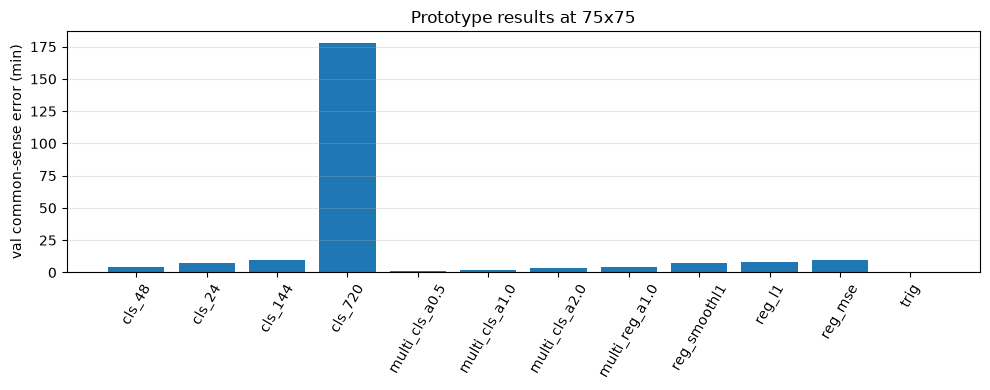

In [14]:
df = pd.DataFrame(RESULTS)
proto = df[df.res == 75].sort_values(["family", "val_mean"]).reset_index(drop=True)
cols = ["name", "family", "val_mean", "val_median", "val_p90", "val_le5", "val_le15", "params", "time_s"]
print(proto[cols].to_string(index=False, float_format=lambda v: f"{v:.3f}"))
proto.to_csv(OUT_DIR / "prototype_75.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(proto["name"], proto["val_mean"])
ax.set(ylabel="val common-sense error (min)", title="Prototype results at 75x75")
ax.tick_params(axis="x", rotation=60)
ax.grid(alpha=0.3, axis="y")
fig.tight_layout()
fig.savefig(OUT_DIR / "prototype_75.png", dpi=200)
plt.show()

In [15]:
best_names = {fam: g.loc[g.val_mean.idxmin(), "name"] for fam, g in proto.groupby("family")}
print(best_names)

data150 = build_data(150)
FINAL = {}
for fam, name in best_names.items():
    model, hist, extras = run(TASKS[name], data150, FINAL_EPOCHS, FINAL_BS, test=True)
    FINAL[name] = {"model": model, "hist": hist, "family": fam, **extras}
    torch.save(model.state_dict(), OUT_DIR / f"{name}_150.pt")

{'classification': 'cls_48', 'multihead': 'multi_cls_a0.5', 'regression': 'reg_smoothl1', 'trig': 'trig'}
res=150 images=(18000, 150, 150) dtype=uint8 labels=(18000, 2)
hour range: 0 11 minute range: 0 59
train/val/test: {'tr': 14400, 'val': 1800, 'te': 1800} mean/std: 0.5963 0.2214
  cls_48 ep  1 train_loss=3.8668 val_mean_err=169.27 min
  cls_48 ep  5 train_loss=1.6701 val_mean_err=91.29 min
  cls_48 ep 10 train_loss=0.7368 val_mean_err=90.43 min
  cls_48 ep 15 train_loss=0.3873 val_mean_err=9.56 min
  cls_48 ep 20 train_loss=0.2339 val_mean_err=8.21 min
  cls_48 ep 25 train_loss=0.1307 val_mean_err=4.15 min
  cls_48 ep 30 train_loss=0.0576 val_mean_err=4.15 min
  cls_48 ep 35 train_loss=0.0286 val_mean_err=3.81 min
  cls_48 ep 40 train_loss=0.0188 val_mean_err=3.77 min
cls_48             res=150 val_mean=3.77 val_median=4.00 val<=5min=0.727 time=2161s
  multi_cls_a0.5 ep  1 train_loss=4.5235 val_mean_err=134.68 min
  multi_cls_a0.5 ep  5 train_loss=2.8020 val_mean_err=70.30 min
  mu

In [16]:
df = pd.DataFrame(RESULTS)
final = df[df.res == 150].reset_index(drop=True)
cols = ["name", "family", "test_mean", "test_median", "test_p90", "test_max", "test_le5", "test_le15",
        "val_mean", "test_mean_hand_only", "params", "time_s"]
cols = [c for c in cols if c in final.columns]
print(final[cols].to_string(index=False, float_format=lambda v: f"{v:.3f}"))
final.to_csv(OUT_DIR / "final_150.csv", index=False)

          name         family  test_mean  test_median  test_p90  test_max  test_le5  test_le15  val_mean  test_mean_hand_only  params   time_s
        cls_48 classification      3.703        4.000     7.000     9.000     0.742      1.000     3.767                  NaN 2233808 2160.694
multi_cls_a0.5      multihead      0.346        0.000     1.000    60.000     0.997      0.997     0.244                  NaN 2239976 3133.643
  reg_smoothl1     regression      9.120        5.962    17.397   358.894     0.438      0.864     9.231                  NaN 2221729 1078.909
          trig           trig      0.348        0.242     0.651    59.344     0.999      0.999     0.333                3.696 2222500 1116.364


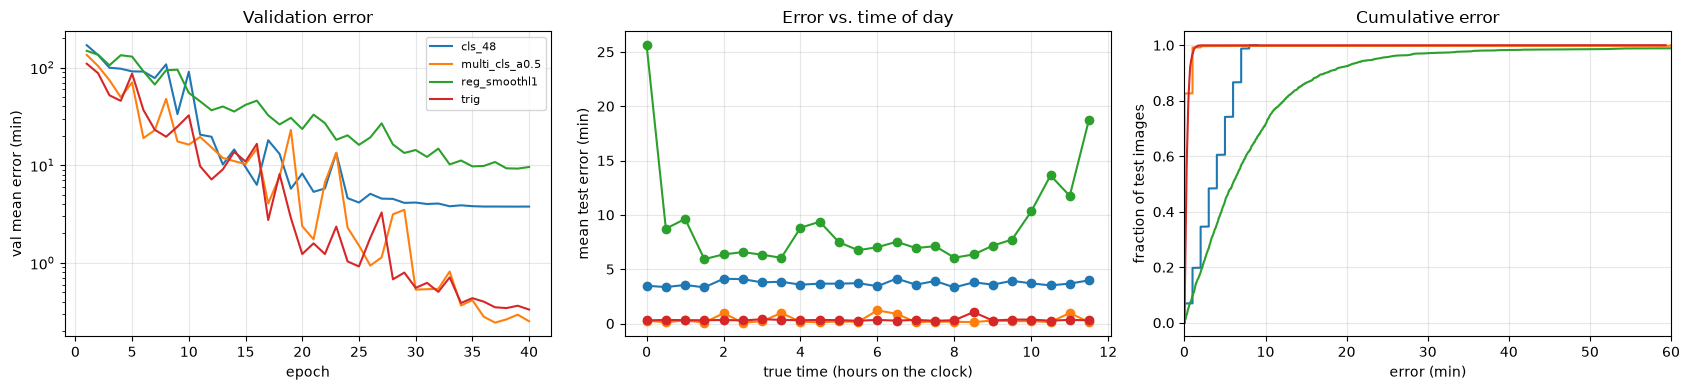

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for name, f in FINAL.items():
    axes[0].plot(range(1, len(f["hist"]["val_mean"]) + 1), f["hist"]["val_mean"], label=name)
    err = f["err"].numpy()
    bins = (f["true"] // 30).numpy()
    means = [err[bins == b].mean() if (bins == b).any() else np.nan for b in range(24)]
    axes[1].plot(np.arange(24) * 0.5, means, marker="o", label=name)
    e = np.sort(err)
    axes[2].plot(e, np.arange(1, len(e) + 1) / len(e), label=name)
axes[0].set(xlabel="epoch", ylabel="val mean error (min)", title="Validation error", yscale="log")
axes[1].set(xlabel="true time (hours on the clock)", ylabel="mean test error (min)", title="Error vs. time of day")
axes[2].set(xlabel="error (min)", ylabel="fraction of test images", title="Cumulative error", xlim=(0, 60))
for a in axes:
    a.grid(alpha=0.3)
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT_DIR / "final_curves.png", dpi=200)
plt.show()

In [18]:
rows = []
for name, f in FINAL.items():
    t, e = f["true"], f["err"]
    near = (t < 30) | (t >= 690)
    rows.append({
        "model": name,
        "n_near_boundary": int(near.sum()),
        "mean_err_near_boundary": e[near].mean().item(),
        "mean_err_elsewhere": e[~near].mean().item(),
    })
boundary = pd.DataFrame(rows)
print(boundary.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
boundary.to_csv(OUT_DIR / "boundary_analysis.csv", index=False)

         model  n_near_boundary  mean_err_near_boundary  mean_err_elsewhere
        cls_48              154                   3.747               3.699
multi_cls_a0.5              154                   0.201               0.360
  reg_smoothl1              154                  21.919               7.923
          trig              154                   0.296               0.353


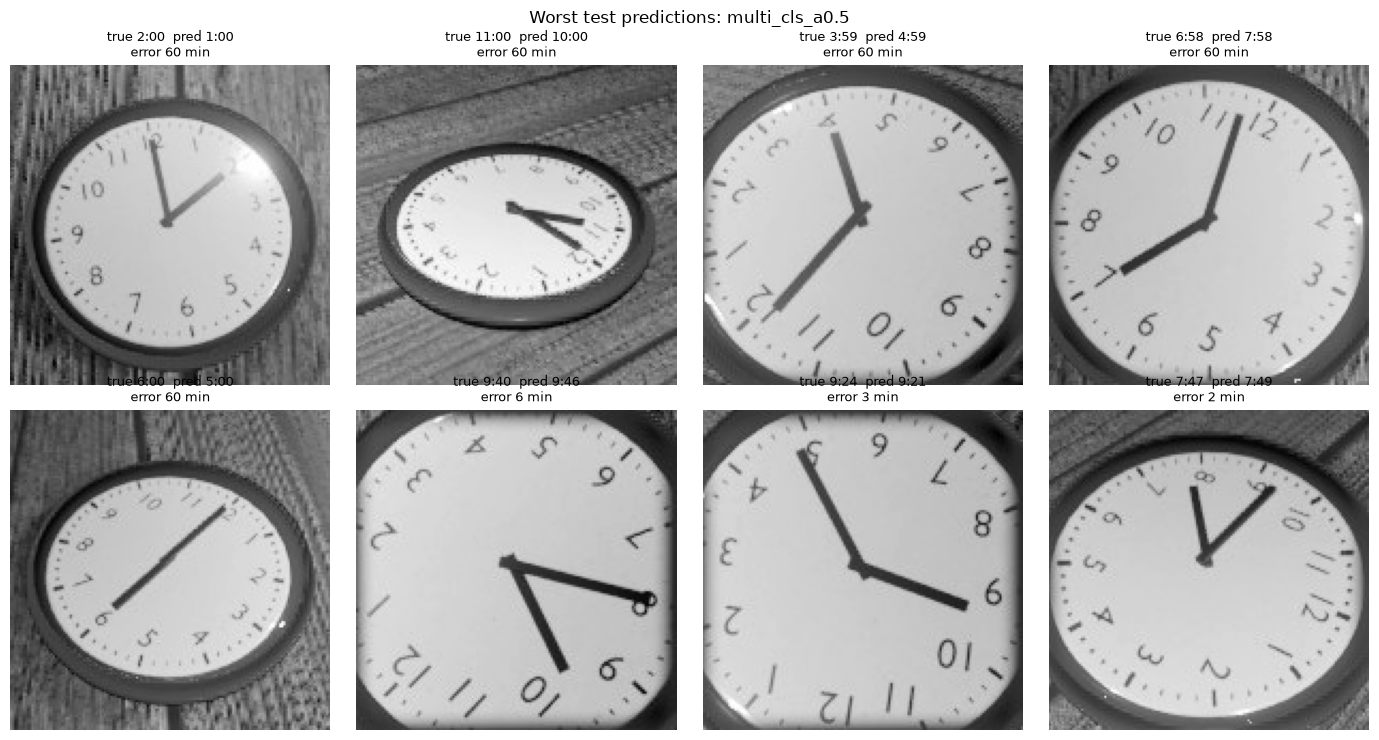

In [19]:
best_name = min(FINAL, key=lambda k: FINAL[k]["err"].mean().item())
f = FINAL[best_name]
worst = torch.argsort(f["err"], descending=True)[:8]
fig, axes = plt.subplots(2, 4, figsize=(14, 7.5))
for ax, i in zip(axes.ravel(), worst.tolist()):
    ax.imshow(data150.x["te"][i].cpu().numpy(), cmap="gray")
    ax.axis("off")
    ax.set_title(f"true {fmt_time(f['true'][i].item())}  pred {fmt_time(f['pred'][i].item())}\nerror {f['err'][i].item():.0f} min", fontsize=9)
fig.suptitle(f"Worst test predictions: {best_name}")
fig.tight_layout()
fig.savefig(OUT_DIR / "worst_predictions.png", dpi=200)
plt.show()